# MLR: PDV and AMV against the TOA budget (CESM2 piControl, Lanczos-filtered)

## The four scenarios

Each index can enter as its **state** or as its **rate of change**.

| | terms |
|---|---|
| 1 | PDV, AMV | 
| 2 | dPDV/dt, dAMV/dt | 
| 3 | dPDV/dt, AMV | 
| 4 | PDV, dAMV/dt |

## What each scenario shows

1. **A small table** (the regression). For each of the two predictors: its coefficient when it is used alone, and its coefficient when both are in the model together. The coefficient says by how many W m⁻² the global-mean TOA changes per 1σ of that predictor.
2. **Three scatter plots**. Left: every year as a point in the plane of the two predictors, coloured by GMTOA. Middle and right: GMTOA against each predictor alone, with the fitted line.
3. **2 × 2 composites**, grouped with the storyline rule of `classify_and_plot`. The years are sorted into four classes in the plane of the two predictors, and TOA and SST are averaged over each class.
4. **Coefficient maps** (optional, `coefficient_maps` in the config). The regression of the table at every grid point: one map per predictor.

**Significance.** As in `04_piControl_state_transition.ipynb`. Regression: t-test with the effective sample size after Metz (1991), L = 50 years, 90 % level; `p` below 0.10 means the coefficient is distinguishable from zero. Composites: t-test across events (runs of consecutive years of a class). Maps are stippled where the test is passed, with field significance by FDR (Wilks 2016).

In [28]:
import pathlib
import warnings
from types import SimpleNamespace

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy import stats
from xarray import SerializationWarning

import functions as fv
from functions import (
    transition,
    classify_and_plot,
    composite_means,
    fdr_sig_masks,
    plot_ivs_2x2,
)

warnings.filterwarnings('ignore', category=SerializationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

## 1 Config

In [ ]:
# --- data: annual anomalies (first 100 years dropped, linear trend removed) and the
# PDV/AMV indices, all written by 01_piControl_annual_anomalies.ipynb ---
anom_dir = pathlib.Path('/path/to/data')  # change to your data directory
index_file = anom_dir / 'PDV_AMV_annual.nc'

# --- results of this notebook: computed once, written here, read back on the next run ---
results_dir = pathlib.Path('/path/to/data/piControl/lanczos')  # change to your output directory
recompute = False        # True: compute the coefficient maps again and overwrite them

# --- decadal storyline fields of section 5, written by 02_piControl_decadal_storylines.ipynb ---
decadal_dir = pathlib.Path('/path/to/data/piControl/decadal')  # change to your decadal directory

# --- decadal filter: Lanczos low-pass on annual means ---
cutoff_years = 10
window = 41              # number of weights; (window - 1) / 2 years are lost at each end

# --- the four scenarios, in the order they are worked through ---
scenarios = [('PDV', 'AMV'), ('dPDV', 'dAMV'), ('dPDV', 'AMV'), ('PDV', 'dAMV')]

# also fit every scenario with the product of its two predictors (e.g. PDV x AMV).
# True adds a line under each table and a third map.
product_term = True

# global mean that the scenario sections are fitted against: 'net', 'SW' or 'LW'
target = 'net'

# fields for the maps of every scenario
map_fields = ['TOA', 'SST']

# --- composites of every scenario ---
# size of the neutral class in percent
alpha_neutral = 20

# also draw the coefficient maps of the regression (one map per predictor)
coefficient_maps = True

# --- uncertainty (t-test), as in the reference notebook ---
ci_percent = 90          # as in Miyamoto et al. (2026)
L_metz = 50              # longest lag (years) in the autocorrelation sum of Metz (1991)

# --- significance on the maps ---
stippling = True         # stipple the grid points that pass the test
use_fdr = True           # True: field significance (FDR, Wilks 2016); False: local test only
alpha_fdr = 0.10         
stipple_step = 4         # a dot on every n-th grid point (lat and lon); larger = fewer dots
stipple_size = 1.5       # dot size (points squared)
stipple_color = '0.25'   # grey: 0 = black, 1 = white

# --- figures ---
point_size = 18          # scatter points: small and faint, there are 1060 of them
point_alpha = 0.35
field_units = {'TOA': 'W m⁻²', 'SST': 'K'}
mean_labels = {'TOA': 'GMTOA ', 'SST': 'mean '}      # written in front of the global mean of a coefficient map
map_cmaps = {'TOA': 'bwr', 'SST': 'RdBu_r'}          
map_levels = {'TOA': np.linspace(-3, 3, 13), 'SST': np.linspace(-0.5, 0.5, 11)}              # coefficient maps
composite_levels = {'TOA': np.linspace(-3, 3, 21), 'SST': np.linspace(-0.5, 0.5, 21)}        # composites
lat_limit = 60           # crop the maps to ±lat_limit degrees, as in the storyline maps; None = whole globe
save_figures = False     # True writes every figure to figure_path(<name>)

## 2 Helpers

The helpers (filter, Metz test, regression, FDR, maps, results on disk) are in `functions.py`. The cell below passes them the settings of the config cell, so the rest of the notebook calls them as before and the config cell stays the only place to edit.

In [30]:
# helpers from functions.py that need no setting
from functions import (
    global_mean, standardise, product_name, to_points, to_map, event_numbers,
    composite_pvalues, pattern_correlation, stack, stack_store,
)

# equal-area, as in the storyline composites
map_projection = ccrs.EqualEarth(central_longitude=180)


# ---- the helpers that use settings of the config cell ----

def lanczos_lowpass(da, dim='time'):
    return fv.lanczos_lowpass(da, cutoff_years, window, dim)


def stipple_mask(p):
    return fv.stipple_mask(p, use_fdr, alpha_fdr, ci_percent)


def finish(fig, name):
    fv.finish(fig, name, save_figures)


def read_anom(name):
    return fv.read_anom(name, anom_dir)


def load_result(name):
    return fv.load_result(name, results_dir, result_settings(), recompute)


# the regressions use the table of standardised predictors built in section 4
def partial_regression(y, terms, term, L=None):
    return fv.partial_regression(y, predictors, terms, term, L_metz if L is None else L, ci_percent)


def fit_series(y, terms):
    return fv.fit_series(y, predictors, terms, L_metz, ci_percent)


def plot_map(ax, da, title, levels, cmap='RdBu_r', fontsize=10, sig=None, step=None, label=None):
    return fv.plot_map(ax, da, title, levels, cmap, fontsize=fontsize, sig=sig,
                       step=stipple_step if step is None else step, stipple_size=stipple_size,
                       stipple_color=stipple_color, lat_limit=lat_limit, label=label)


# results on disk: settings the stored results depend on
def result_settings():
    return dict(cutoff_years=cutoff_years, window=window, L_metz=L_metz)


def save_result(ds, name):
    fv.save_result(ds, name, results_dir, result_settings(), '03_piControl_lowpass_MLR.ipynb')


# how a predictor and a target are written in titles; the product terms are
# added in section 4
term_labels = {'PDV': 'PDV', 'AMV': 'AMV', 'dPDV': 'dPDV/dt', 'dAMV': 'dAMV/dt'}
target_labels = {'net': 'GMTOA', 'SW': 'global-mean SW', 'LW': 'global-mean LW'}

In [31]:
# coefficient maps: (scenario, field, term) -> (coefficient, p-value), read back if written
# before; new ones are computed by coefficient_map and written after scenario 4
coef_cache, coef_cache_new = {}, False
saved = load_result('mlr_coef_maps')
if saved is not None:
    for k in range(saved.sizes['map']):
        one = saved.isel(map=k)
        key = (str(one['scenario'].values), str(one['field'].values), str(one['term'].values))
        coef_cache[key] = tuple(one[v].drop_vars(['scenario', 'field', 'term']) for v in ('coef', 'p'))


def coefficient_map(tag, field_name, term, terms):
    """Coefficient and p-value map of ``term`` in the MLR on ``terms``.

    From coef_cache if there, otherwise computed (slow: autocorrelation of the field
    up to L_metz) and added to it.
    """
    global coef_cache_new
    key = (tag, field_name, term)
    if key not in coef_cache:
        (y, valid), template = map_sources[field_name]
        fit = partial_regression(y, terms, term)
        coef_cache[key] = (to_map(fit['coef'], valid, template), to_map(fit['p'], valid, template))
        coef_cache_new = True
    return coef_cache[key]

read /Users/liobabraun/Desktop/Uni_Leipzig/MA/server/data/piControl/lanczos/mlr_coef_maps.nc


In [32]:
# ---- one scenario: fit, table, scatter plots, composites, maps ----

def build_scenario(xcol, ycol):
    """Fit one scenario for the global mean set as ``target`` in the config.

    ``xcol`` goes on the x-axis and ``ycol`` on the y-axis of the scatter plot.
    Each predictor is fitted alone and both are fitted together; with
    product_term set, a third fit adds the product of the two.
    """
    y = gm[target].values
    terms = [xcol, ycol]
    product = product_name(xcol, ycol)
    return SimpleNamespace(
        xcol=xcol, ycol=ycol, terms=terms, product=product, tag=f'{xcol}_{ycol}',
        name=f'{term_labels[xcol]} and {term_labels[ycol]}',
        together=fit_series(y, terms),
        alone=pd.concat([fit_series(y, [term]) for term in terms]),
        with_product=fit_series(y, terms + [product]) if product_term else None,
        classes=None, class_labels=None, maps={},
    )


def summary(sc):
    """Coefficient of each predictor alone and with both in the model."""
    table = pd.DataFrame({
        'alone': sc.alone['coef'],
        'together': sc.together['coef'],
        'low': sc.together['low'],
        'high': sc.together['high'],
        'p': sc.together['p'],
        'R2 alone': sc.alone['R2'],
    })
    print(f'{target_labels[target]} on {sc.name}: coefficients in W m-2 per sigma')
    print(f'low, high: {ci_percent} % interval of the coefficient with both in the model')
    display(table.round(3))
    print(f"R2 with both in the model: {sc.together['R2'].iloc[0]:.3f}")

    if product_term:
        row = sc.with_product.loc[sc.product]
        verdict = 'the two effects add up' if row['p'] >= 1 - ci_percent / 100 \
            else 'the effect of one depends on the other'
        print()
        print(f"product term {term_labels[sc.product]}: {row['coef']:+.3f} "
              f"[{row['low']:+.3f}, {row['high']:+.3f}], p = {row['p']:.3f} -> {verdict}")
        print(f"R2 with the product term: {row['R2']:.3f}")


def scatter_row(sc):
    """The three scatter views of one scenario.

    Left: the plane of the two predictors, every year coloured by the global
    mean. Middle and right: the global mean against each predictor alone,
    with the single regression line.
    """
    values = gm[target].values
    x, y = predictors[sc.xcol].values, predictors[sc.ycol].values
    vlim = float(np.quantile(np.abs(values), 0.95))
    unit = f'{target_labels[target]} (W m⁻²)'

    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8), constrained_layout=True)

    im = axes[0].scatter(x, y, c=values, cmap='RdBu_r', vmin=-vlim, vmax=vlim,
                         s=point_size, alpha=point_alpha, edgecolors='none')
    axes[0].set_xlabel(f'{term_labels[sc.xcol]} (σ)')
    axes[0].set_ylabel(f'{term_labels[sc.ycol]} (σ)')
    axes[0].set_title(f"Both together: R² = {sc.together['R2'].iloc[0]:.3f}", fontsize=11)
    fig.colorbar(im, ax=axes[0]).set_label(unit, fontsize=9)

    for ax, col, index_values in ((axes[1], sc.xcol, x), (axes[2], sc.ycol, y)):
        ax.scatter(index_values, values, s=point_size, alpha=point_alpha,
                   color='tab:blue', edgecolors='none')
        slope, intercept, r, _, _ = stats.linregress(index_values, values)
        xx = np.linspace(index_values.min(), index_values.max(), 100)
        ax.plot(xx, slope * xx + intercept, 'k--', lw=1.5, zorder=5)
        ax.set_xlabel(f'{term_labels[col]} (σ)')
        ax.set_ylabel(unit)
        ax.set_title(f'{term_labels[col]} alone: R² = {r ** 2:.3f}, '
                     f'slope = {slope:+.3f} W m⁻² per σ', fontsize=11)

    for ax in axes:
        ax.axhline(0, color='grey', lw=0.7, ls='--', zorder=0)
        ax.axvline(0, color='grey', lw=0.7, ls='--', zorder=0)
        for spine in ax.spines.values():
            spine.set_visible(False)

    finish(fig, f'MLR_scatter_{sc.tag}')


def classify_scenario(sc):
    """Storyline classes of the years in the plane of the two predictors.

    The rule of classify_and_plot: neutral class
    inside the Mahalanobis ellipse, dividing lines along the axes of maximal
    variance), applied to the 1060 filtered years of this scenario. The
    classification figure it draws always labels the axes PDV and AMV; here
    x is the first and y the second predictor of the scenario.
    """
    x, y = predictors[sc.xcol].values, predictors[sc.ycol].values
    _, classes, _, _, _, _ = classify_and_plot(
        pdv_list=[x], amv_list=[y], alpha=alpha_neutral, ellipse_levels=(0.5, 0.8, 0.95),
    )
    sc.classes = np.asarray(classes)

    xl, yl = term_labels[sc.xcol], term_labels[sc.ycol]
    sc.class_labels = {1: f'{xl}+ / {yl}+', 2: f'{xl}− / {yl}+',
                       3: f'{xl}− / {yl}−', 4: f'{xl}+ / {yl}−'}

    print()
    print(f'classes in the plane {xl} (x) against {yl} (y)')
    print(f'  neutral: {int((sc.classes == 0).sum())} years')
    for i, label in sc.class_labels.items():
        selected = sc.classes == i
        print(f'  {label}: {int(selected.sum())} years in {int(event_numbers(selected).max())} events')


def annotate_gmtoa(fig, values):
    """Write the GMTOA of each class into the lower left corner of its panel.

    ``fig`` comes from plot_ivs_2x2, whose panels are in the order [top-left,
    top-right, bottom-left, bottom-right] = classes 2, 1, 3, 4. ``values``
    maps the class to its global-mean net TOA anomaly in W m-2. Same box as
    in plot_map.
    """
    for ax, i in zip(fig.axes[:4], (2, 1, 3, 4)):
        ax.text(0.02, 0.05, f'GMTOA {values[i]:+.3f}', transform=ax.transAxes,
                fontsize=10, va='bottom', ha='left',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='none'))


def scenario_composites(sc, field_name):
    """2x2 composite of one field over the four classes of the scenario.

    Mean of the field over all years of a class, drawn with plot_ivs_2x2 as
    every storyline composite of the project: x+ on the right, y+ on top.
    The number in the corner is the GMTOA of the class, for every field.
    Stippling: t-test across events (runs of consecutive years), then FDR.
    """
    if sc.classes is None:
        classify_scenario(sc)

    field = fields[field_name].transpose('time', 'lat', 'lon')
    means, sig, gmtoa = {}, {}, {}
    for i in sc.class_labels:
        selected = sc.classes == i
        means[i] = field.isel(time=np.flatnonzero(selected)).mean('time').to_dataset(name=field_name)
        gmtoa[i] = float(gm['net'].values[selected].mean())
        p = composite_pvalues(field, selected)
        if stippling:
            sig[i] = stipple_mask(p)

    fig = plot_ivs_2x2(
        means, variable=field_name, levels=composite_levels[field_name],
        cmap=map_cmaps[field_name], sig_masks=sig if stippling else None, lat_limit=lat_limit,
        cbar_label=f'{field_name} anomaly ({field_units[field_name]})',
        stipple_step=stipple_step, stipple_size=stipple_size, stipple_color=stipple_color,
    )
    # plot_ivs_2x2 writes the fixed PDV/AMV titles; replace them
    for ax, i in zip(fig.axes[:4], (2, 1, 3, 4)):
        ax.set_title(sc.class_labels[i], fontsize=12, fontweight='bold')
    annotate_gmtoa(fig, gmtoa)
    finish(fig, f'MLR_composites_{sc.tag}_{field_name}')


def scenario_maps(sc, field_name):
    """The regression of the scenario at every grid point: one map per predictor.

    Each of the two maps is the coefficient of that predictor in the MLR with
    both predictors; the figure title names the model. With product_term set,
    a third map shows the coefficient of the product in the model with all
    three terms. Slow: every map needs the autocorrelation of a field up to
    L_metz.
    """
    y, valid = points[field_name]
    template = fields[field_name]

    # (term, terms of the model it is taken from, title)
    panels = [(term, sc.terms, term_labels[term]) for term in sc.terms]
    if product_term:
        panels.append((sc.product, sc.terms + [sc.product],
                       f'Product term {term_labels[sc.product]}'))

    fig, axes = plt.subplots(
        1, len(panels), figsize=(5.5 * len(panels), 3.8),
        subplot_kw={'projection': map_projection}, constrained_layout=True,
    )
    for ax, (term, terms, title) in zip(axes, panels):
        coef, p = coefficient_map(sc.tag, field_name, term, terms)
        sig = stipple_mask(p) if stippling else None
        sc.maps[(field_name, term)] = coef
        im = plot_map(ax, coef, title, map_levels[field_name], cmap=map_cmaps[field_name],
                      sig=sig, label=mean_labels[field_name])
    cbar = fig.colorbar(im, ax=axes, orientation='horizontal', shrink=0.5, aspect=40, pad=0.08)
    cbar.set_label(f'{field_name} anomaly ({field_units[field_name]} per σ)')
    fig.suptitle(f'{field_name}: MLR on {sc.name}')
    finish(fig, f'MLR_maps_{sc.tag}_{field_name}')

## 3 Data and indices

Same preprocessing as before: annual mean → drop the first 100 years → remove the linear trend → 10-yr Lanczos low-pass. The SST field (ocean only) is added as a second field for the maps.

In [33]:
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

In [34]:
# TOA, all downward positive: SW = absorbed solar (rsdt - rsut), LW = -OLR, net = SW + LW
sw_anom = read_anom('SWTOA')
lw_anom = read_anom('LWTOA')

sw_dec = lanczos_lowpass(sw_anom)
lw_dec = lanczos_lowpass(lw_anom)

# decadal TOA net field, as anomaly from its own time mean
toa_dec = sw_dec + lw_dec
toa_dec = toa_dec - toa_dec.mean('time')

# global means; every step above is linear, so net = SW + LW holds exactly
gm = xr.Dataset({
    'net': global_mean(toa_dec),
    'SW': global_mean(sw_dec),
    'LW': global_mean(lw_dec),
})
gm = gm - gm.mean('time')

del sw_anom, lw_anom, sw_dec, lw_dec
print(f"decadal record: {toa_dec.sizes['time']} years")
print(f"std of decadal GMTOA: {float(gm['net'].std()):.3f} W m-2")

decadal record: 1060 years
std of decadal GMTOA: 0.129 W m-2


In [35]:
# Indices from 01_piControl_annual_anomalies.ipynb. They are already annual anomalies
# (first 100 years dropped, detrended), so only the filter is applied here.
indices = xr.open_dataset(index_file, decode_times=time_coder)
pdv = lanczos_lowpass(indices['PDV'].load()).rename('PDV')
amv = lanczos_lowpass(indices['AMV'].load()).rename('AMV')

# rate of change of the decadal index (centred difference, per year)
pdv_rate = transition(pdv).rename('PDV_rate')
amv_rate = transition(amv).rename('AMV_rate')

# decadal SST field, land stays NaN
sst_dec = lanczos_lowpass(read_anom('SST'))
sst_dec = sst_dec - sst_dec.mean('time')

# stops here if the indices and the fields are not on the same years and grid
xr.align(pdv, amv, pdv_rate, amv_rate, gm, toa_dec, sst_dec, join='exact')

# fields for the maps, as float32, and as (time, points) arrays for the regressions
fields = {'TOA': toa_dec.astype('float32'), 'SST': sst_dec.astype('float32')}
fields = {name: fields[name] for name in map_fields}
points = {name: to_points(da) for name, da in fields.items()}

del toa_dec, sst_dec
for name, (values, valid) in points.items():
    print(f'{name}: {values.shape[0]} years, {values.shape[1]} of {valid.size} grid points')

# where coefficient_map finds the data of a field
map_sources = {name: (points[name], fields[name]) for name in fields}

TOA: 1060 years, 55296 of 55296 grid points
SST: 1060 years, 36278 of 55296 grid points


## 4 Predictors

All four predictors are standardised (mean 0, standard deviation 1), so every coefficient reads as W m⁻² per σ. The product of each scenario is the product of its two standardised predictors.

The correlation table says which predictors share signal:

- **PDV with dPDV, AMV with dAMV: about 0.** Whether an index is high says nothing about whether it is rising.
- **PDV with AMV, dPDV with dAMV: clearly negative.** These are the pairs of scenarios 1 and 2; there "alone" and "together" can differ.
- **PDV with dAMV, AMV with dPDV:** the pairs of scenarios 3 and 4.

In [36]:
predictors = pd.DataFrame(
    {
        'PDV': standardise(pdv).values,
        'AMV': standardise(amv).values,
        'dPDV': standardise(pdv_rate).values,
        'dAMV': standardise(amv_rate).values,
    },
    index=pdv['time'].dt.year.values,
)

print('correlations of the predictors')
print(predictors.corr().round(2).to_string())

# the product of every scenario, as one more column each
for xcol, ycol in scenarios:
    predictors[product_name(xcol, ycol)] = predictors[xcol] * predictors[ycol]
    term_labels[product_name(xcol, ycol)] = f'{term_labels[xcol]} × {term_labels[ycol]}'

correlations of the predictors
       PDV   AMV  dPDV  dAMV
PDV   1.00 -0.27 -0.00  0.34
AMV  -0.27  1.00 -0.28  0.01
dPDV -0.00 -0.28  1.00 -0.39
dAMV  0.34  0.01 -0.39  1.00


---

# Scenario 1: PDV and AMV (states)

GMTOA on PDV and AMV: coefficients in W m-2 per sigma
low, high: 90 % interval of the coefficient with both in the model


,alone,together,low,high,p,R2 alone
PDV,-0.034,-0.047,-0.060,-0.034,0.0,0.072
AMV,-0.033,-0.046,-0.058,-0.033,0.0,0.064


R2 with both in the model: 0.187

product term PDV × AMV: +0.007 [-0.006, +0.019], p = 0.370 -> the two effects add up
R2 with the product term: 0.189


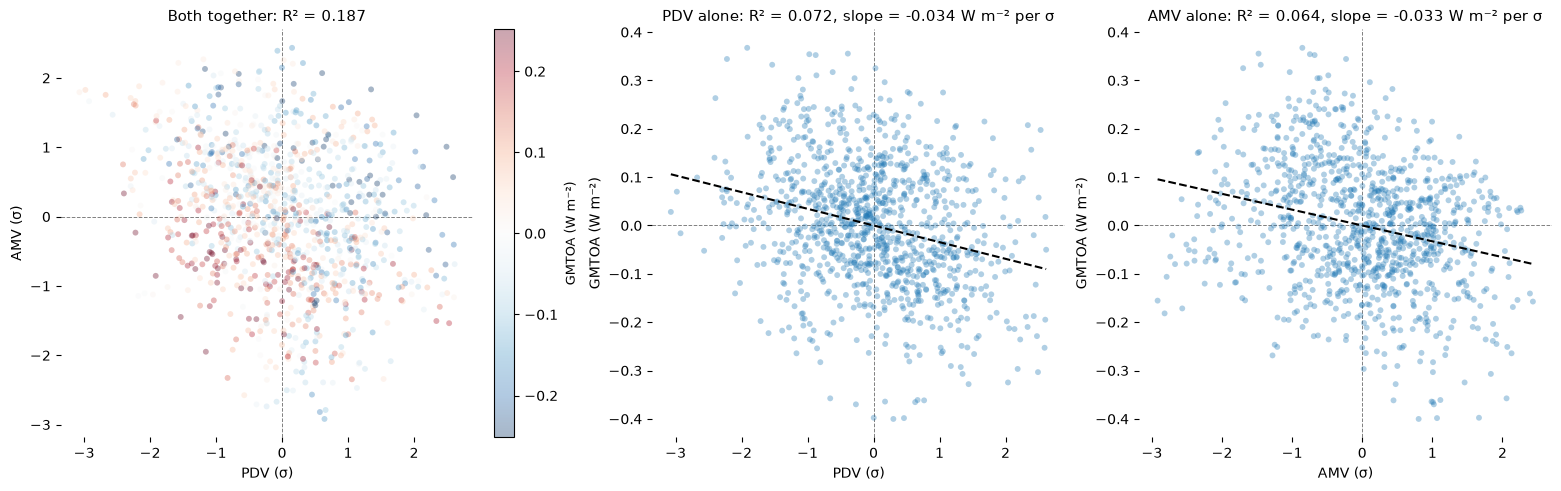

In [37]:
sc1 = build_scenario('PDV', 'AMV')
summary(sc1)
scatter_row(sc1)

Classifying data with alpha=20...


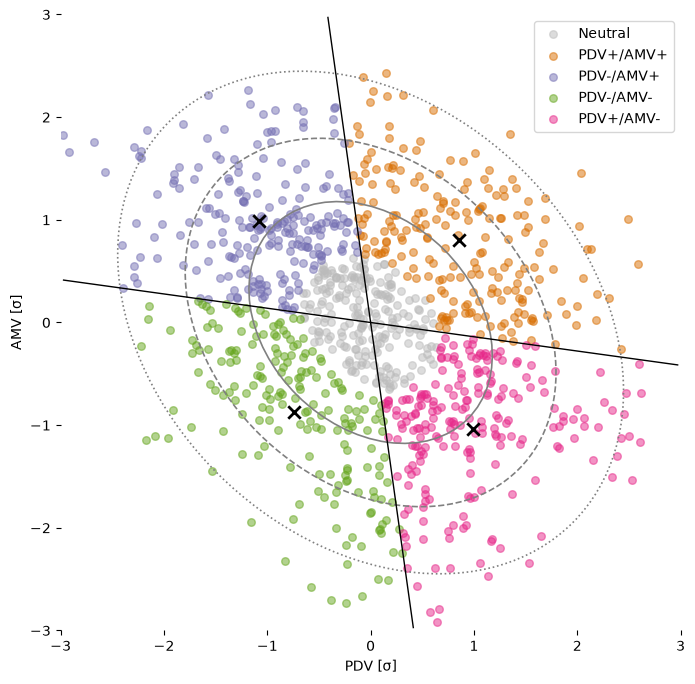

PDV-AMV correlation: r = -0.273
Neutral: 218 points
PDV+/AMV+: 207 points
PDV-/AMV+: 223 points
PDV-/AMV-: 193 points
PDV+/AMV-: 219 points

classes in the plane PDV (x) against AMV (y)
  neutral: 218 years
  PDV+ / AMV+: 207 years in 38 events
  PDV− / AMV+: 223 years in 48 events
  PDV− / AMV−: 193 years in 38 events
  PDV+ / AMV−: 219 years in 43 events


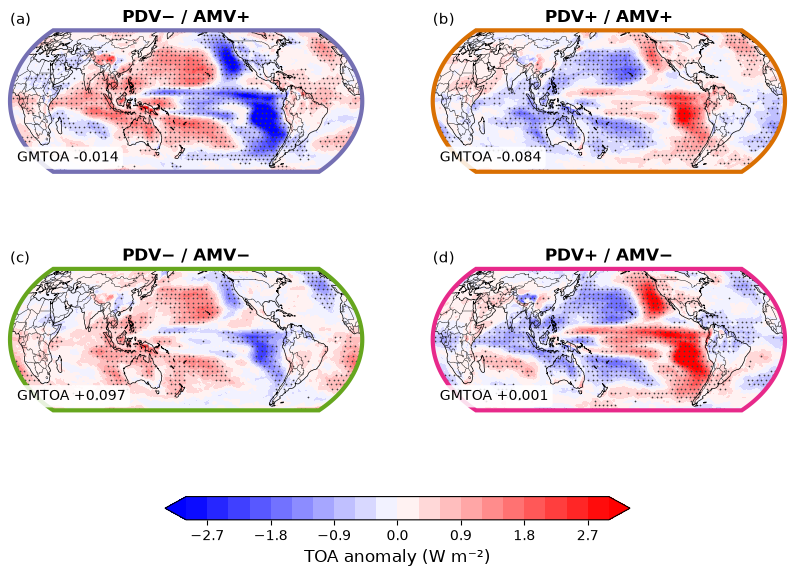

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


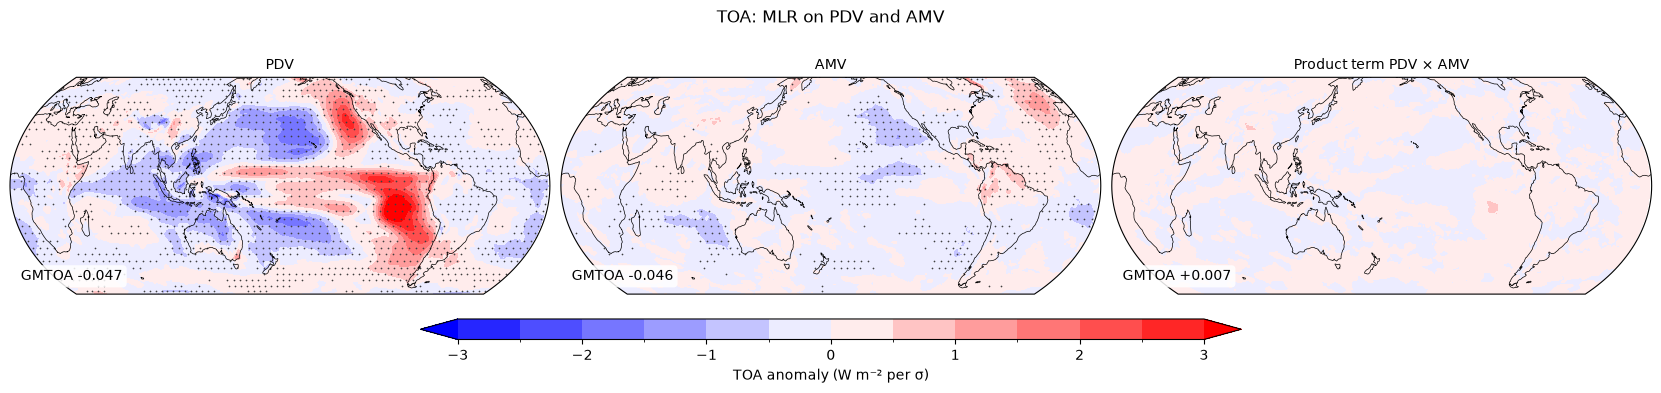

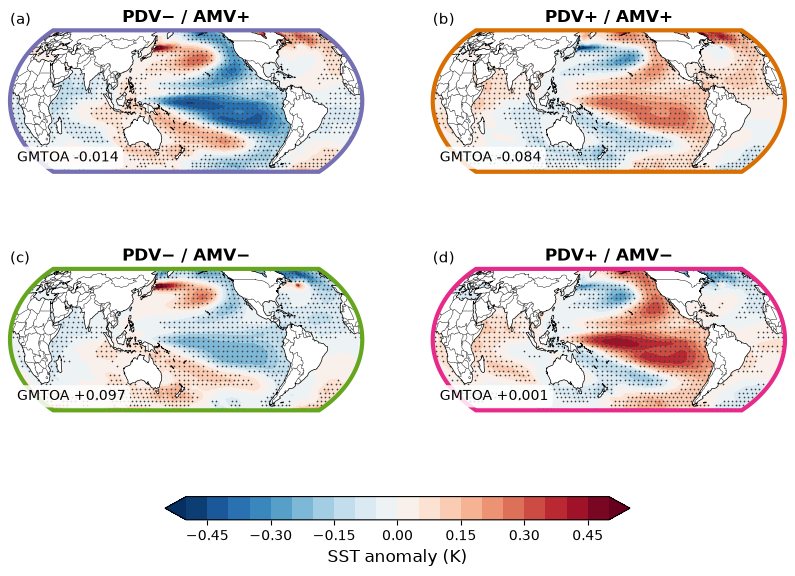

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


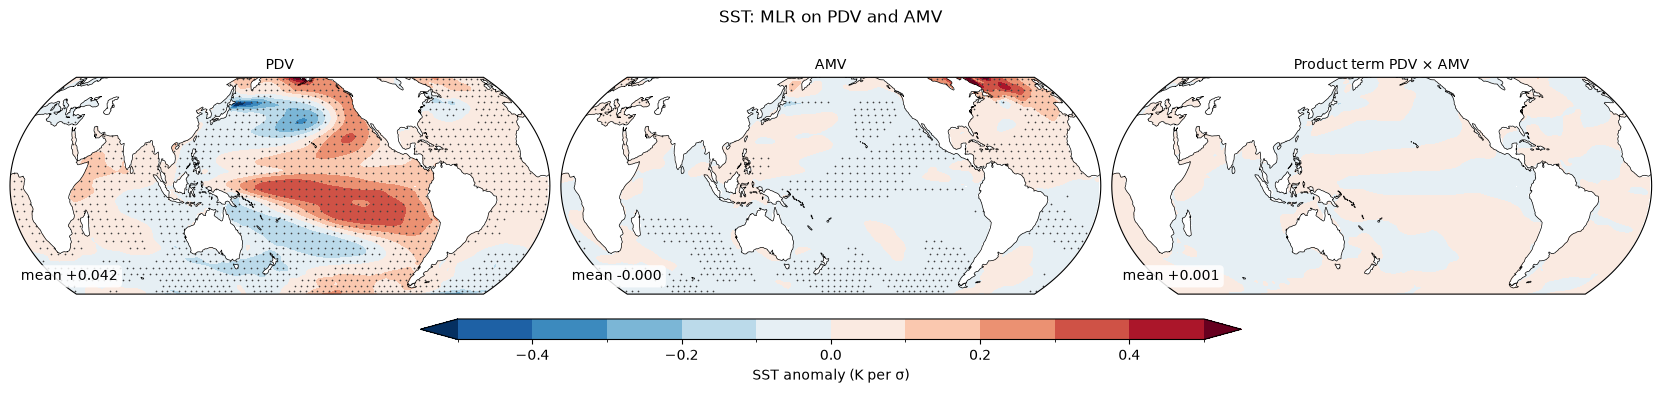

In [38]:
for field_name in map_fields:
    scenario_composites(sc1, field_name)
    if coefficient_maps:
        scenario_maps(sc1, field_name)

---

# Scenario 2: dPDV/dt and dAMV/dt (rates of change)

GMTOA on dPDV/dt and dAMV/dt: coefficients in W m-2 per sigma
low, high: 90 % interval of the coefficient with both in the model


,alone,together,low,high,p,R2 alone
dPDV,0.059,0.047,0.033,0.061,0.0,0.210
dAMV,-0.050,-0.031,-0.045,-0.017,0.0,0.148


R2 with both in the model: 0.259

product term dPDV/dt × dAMV/dt: +0.005 [-0.003, +0.014], p = 0.302 -> the two effects add up
R2 with the product term: 0.260


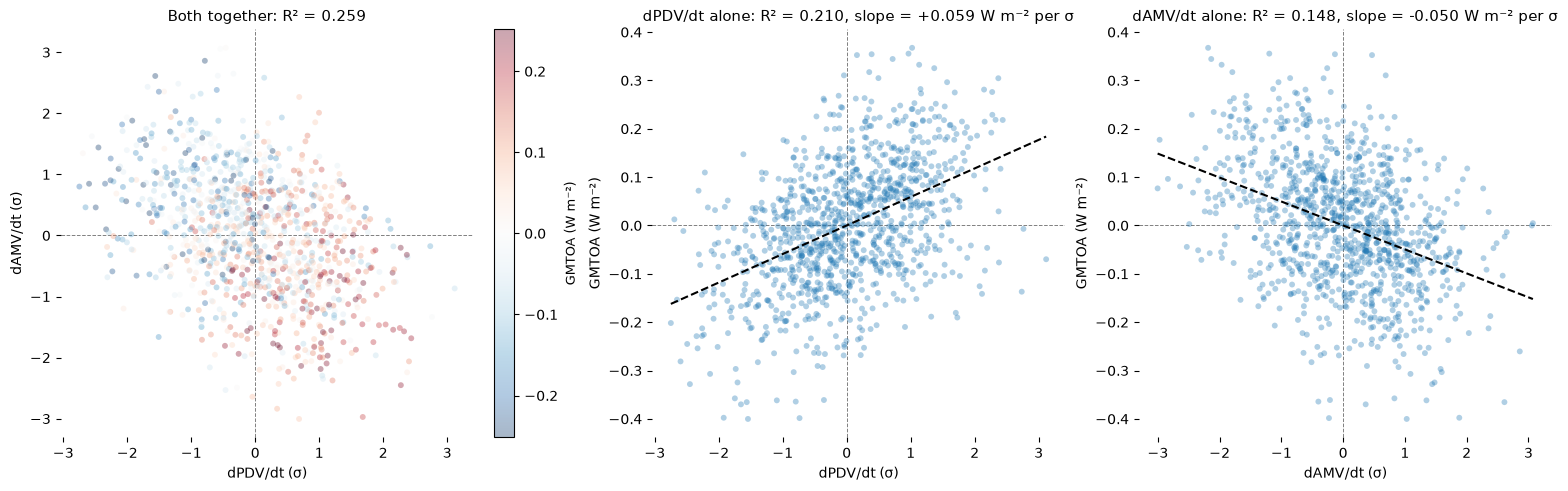

In [39]:
sc2 = build_scenario('dPDV', 'dAMV')
summary(sc2)
scatter_row(sc2)

Classifying data with alpha=20...


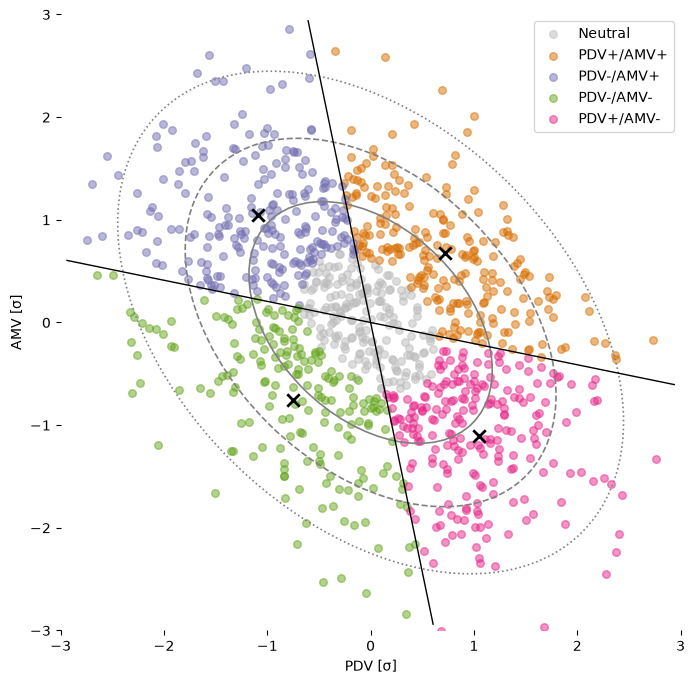

PDV-AMV correlation: r = -0.395
Neutral: 193 points
PDV+/AMV+: 226 points
PDV-/AMV+: 224 points
PDV-/AMV-: 193 points
PDV+/AMV-: 224 points

classes in the plane dPDV/dt (x) against dAMV/dt (y)
  neutral: 193 years
  dPDV/dt+ / dAMV/dt+: 226 years in 59 events
  dPDV/dt− / dAMV/dt+: 224 years in 64 events
  dPDV/dt− / dAMV/dt−: 193 years in 56 events
  dPDV/dt+ / dAMV/dt−: 224 years in 65 events


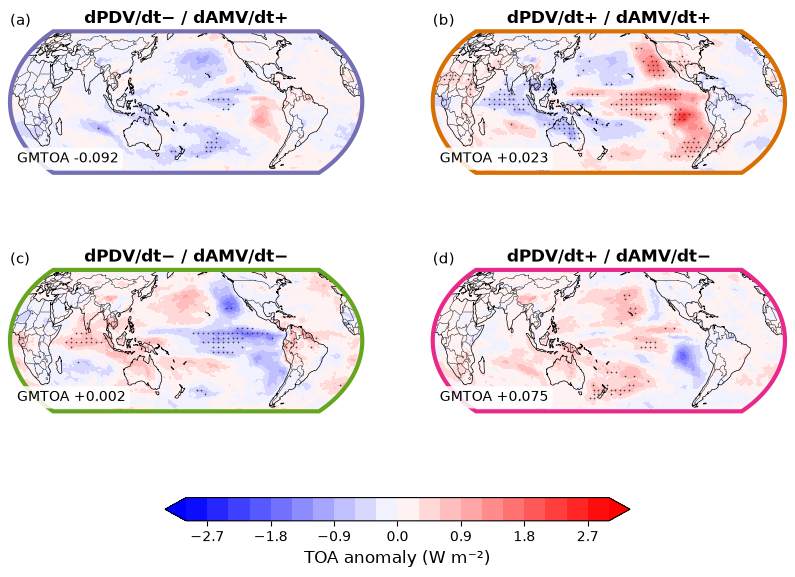

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


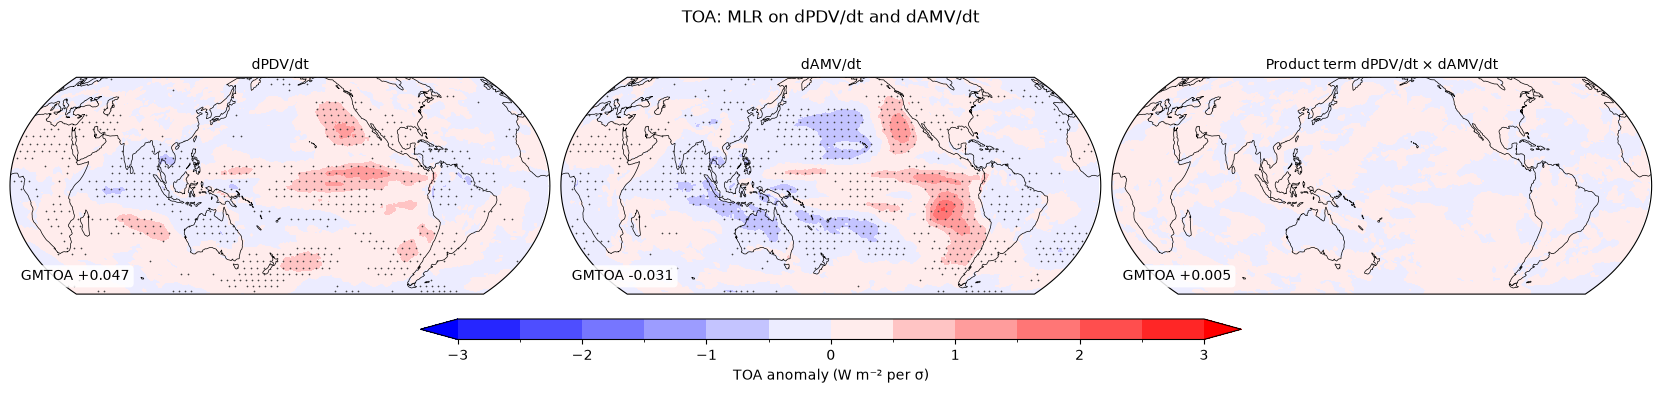

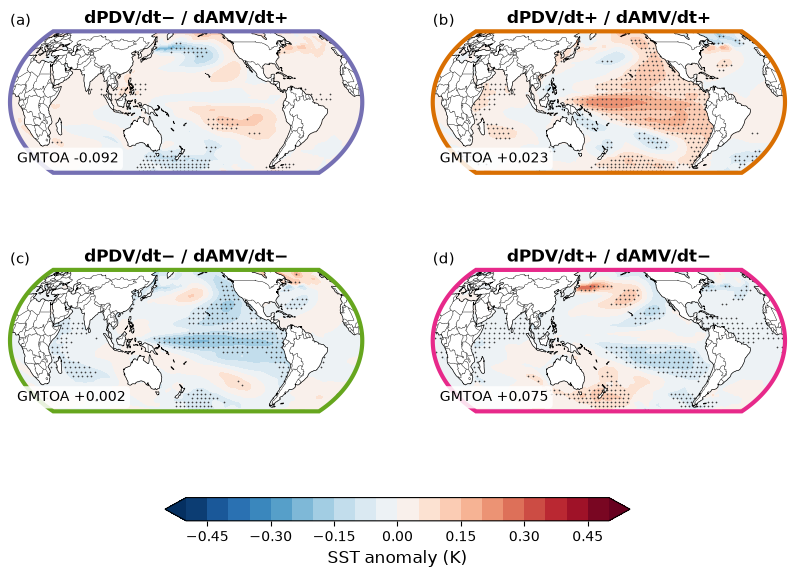

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


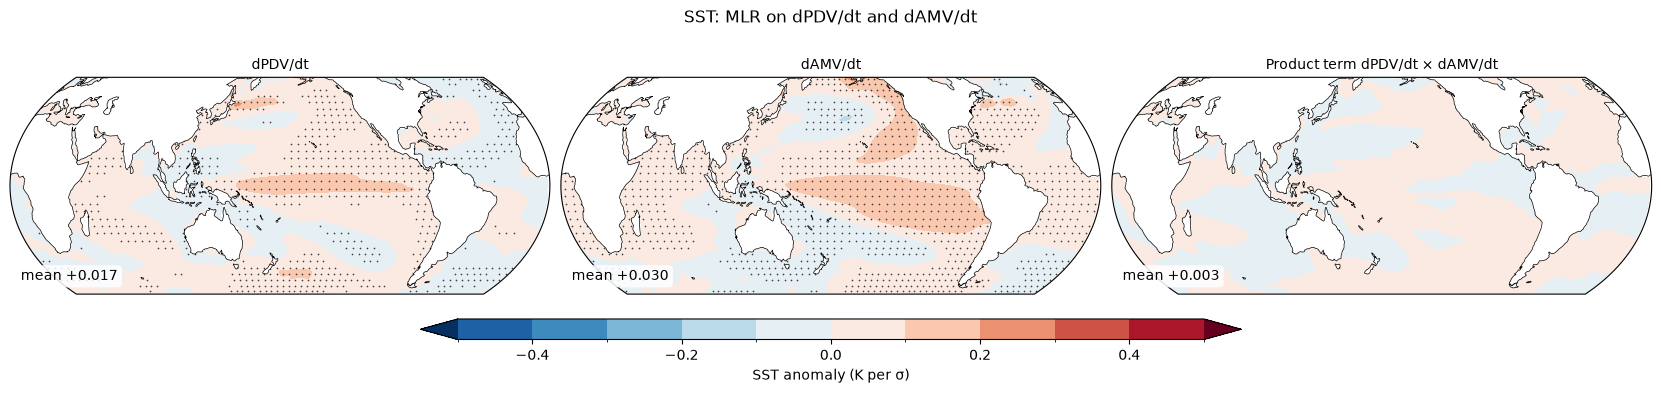

In [40]:
for field_name in map_fields:
    scenario_composites(sc2, field_name)
    if coefficient_maps:
        scenario_maps(sc2, field_name)

---

# Scenario 3: dPDV/dt and AMV

GMTOA on dPDV/dt and AMV: coefficients in W m-2 per sigma
low, high: 90 % interval of the coefficient with both in the model


,alone,together,low,high,p,R2 alone
dPDV,0.059,0.054,0.041,0.068,0.000,0.210
AMV,-0.033,-0.018,-0.030,-0.005,0.019,0.064


R2 with both in the model: 0.227

product term dPDV/dt × AMV: -0.003 [-0.014, +0.009], p = 0.703 -> the two effects add up
R2 with the product term: 0.227


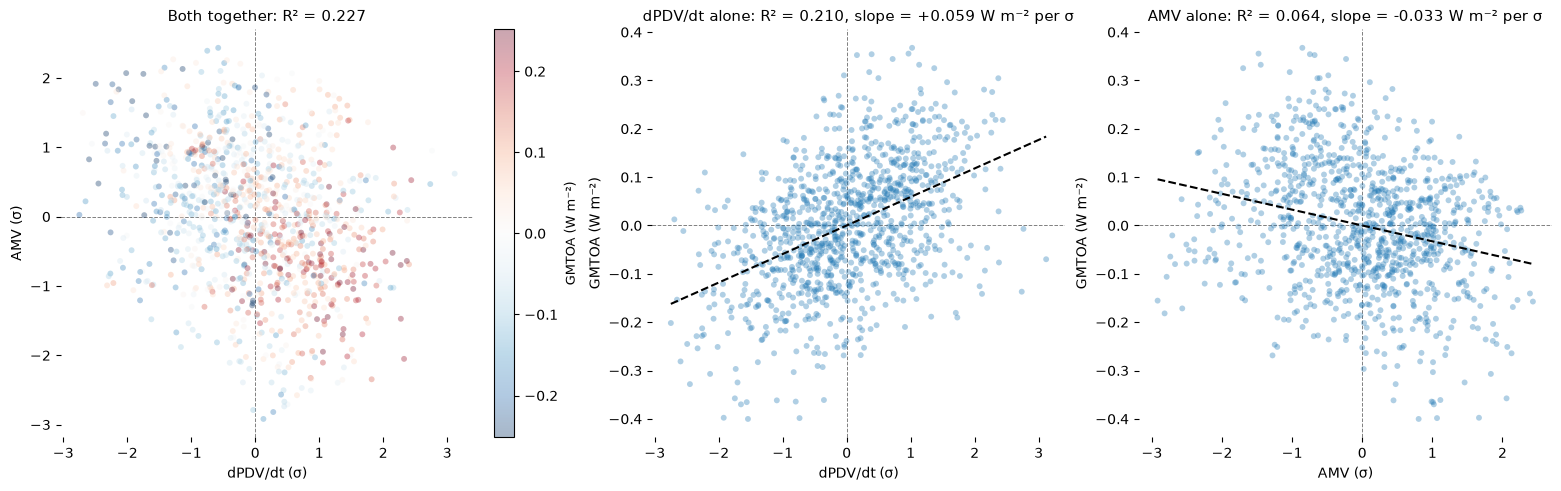

In [41]:
sc3 = build_scenario('dPDV', 'AMV')
summary(sc3)
scatter_row(sc3)

Classifying data with alpha=20...


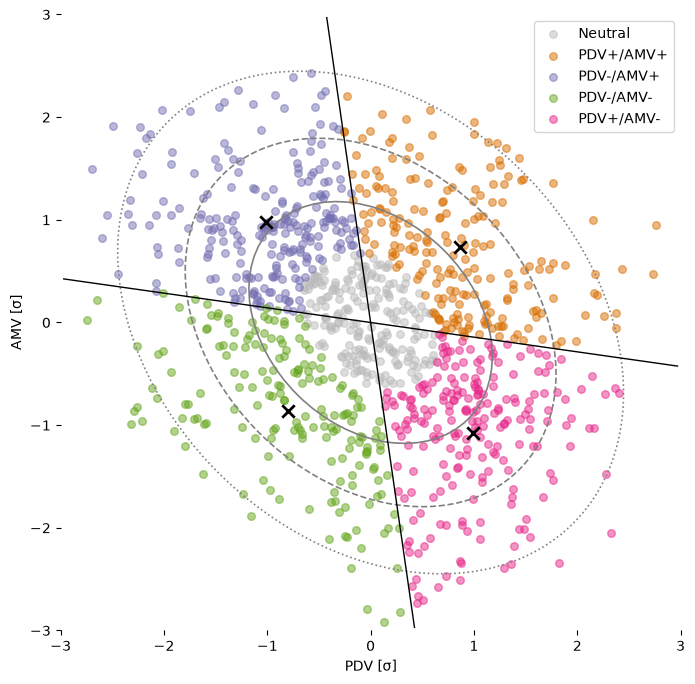

PDV-AMV correlation: r = -0.280
Neutral: 209 points
PDV+/AMV+: 209 points
PDV-/AMV+: 239 points
PDV-/AMV-: 184 points
PDV+/AMV-: 219 points

classes in the plane dPDV/dt (x) against AMV (y)
  neutral: 209 years
  dPDV/dt+ / AMV+: 209 years in 51 events
  dPDV/dt− / AMV+: 239 years in 56 events
  dPDV/dt− / AMV−: 184 years in 41 events
  dPDV/dt+ / AMV−: 219 years in 52 events


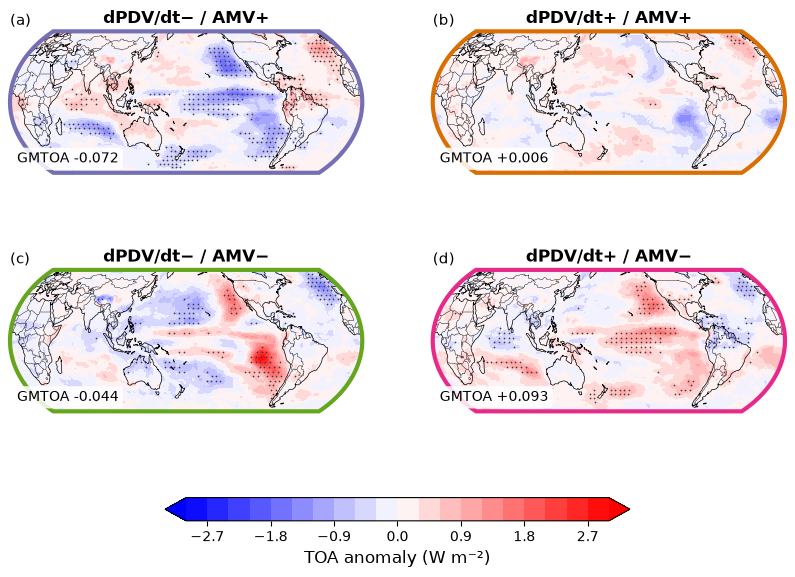

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


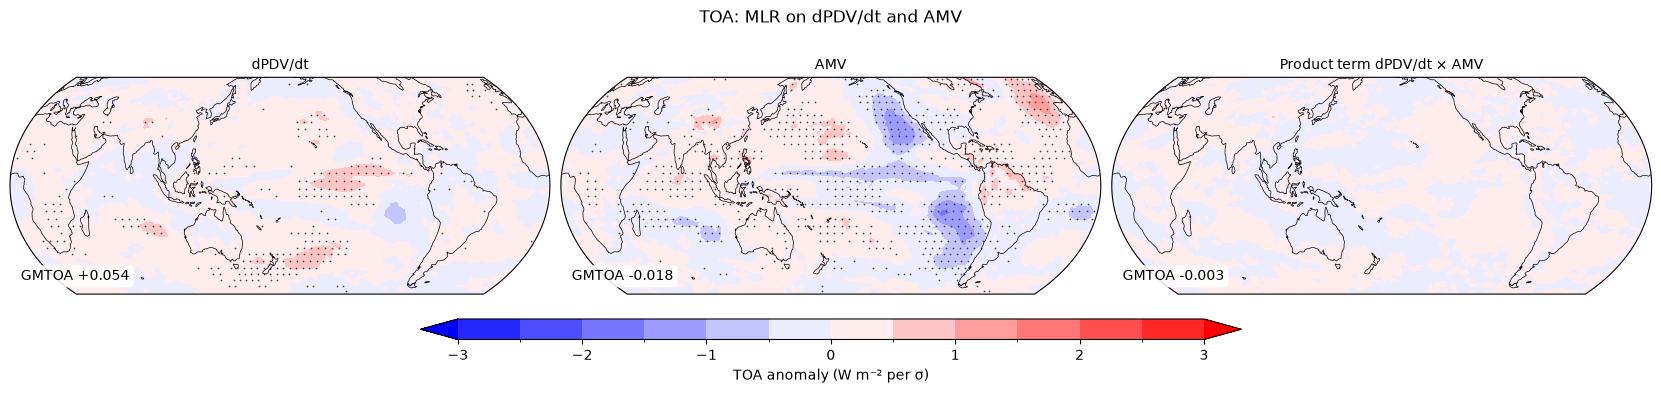

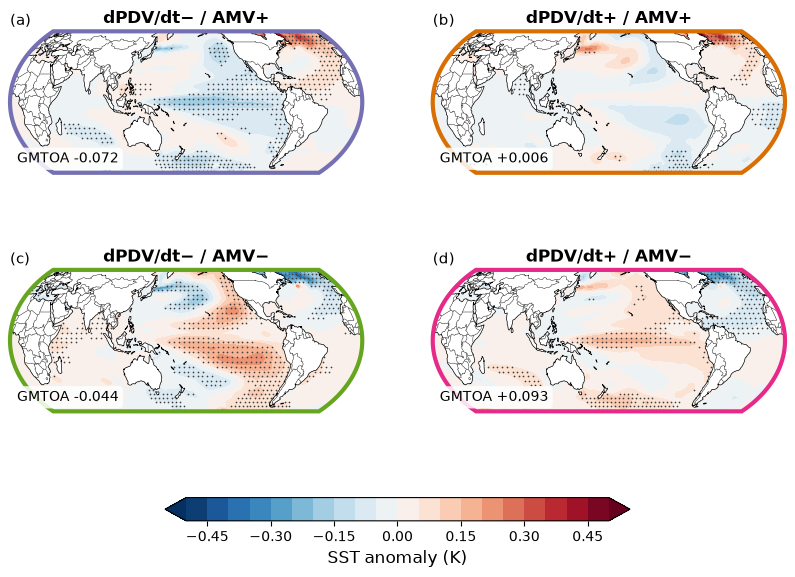

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


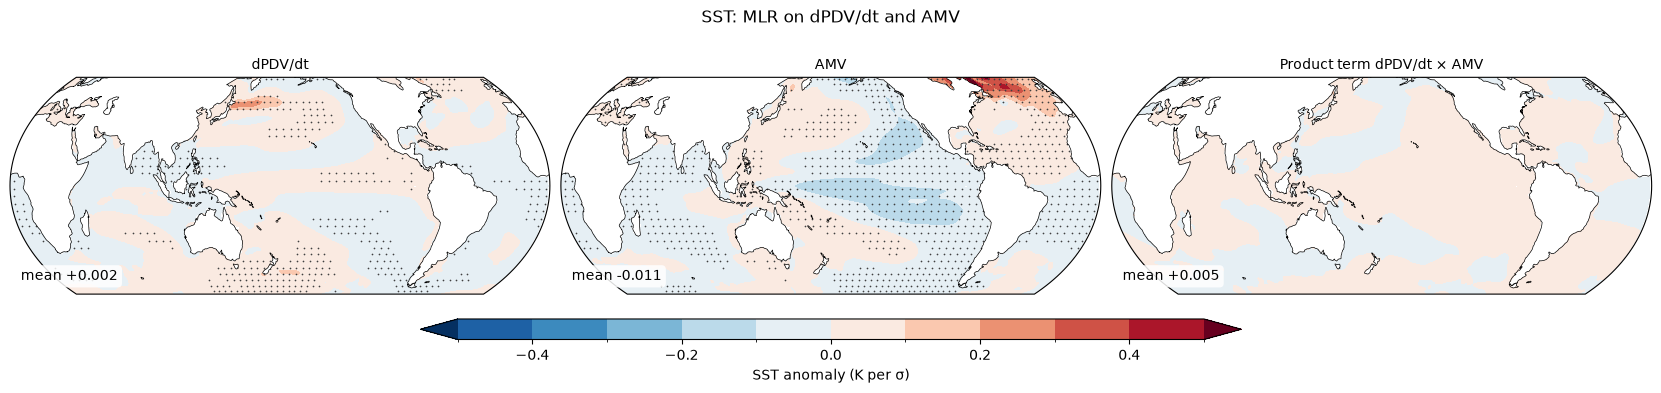

In [42]:
for field_name in map_fields:
    scenario_composites(sc3, field_name)
    if coefficient_maps:
        scenario_maps(sc3, field_name)

---

# Scenario 4: PDV and dAMV/dt

GMTOA on PDV and dAMV/dt: coefficients in W m-2 per sigma
low, high: 90 % interval of the coefficient with both in the model


,alone,together,low,high,p,R2 alone
PDV,-0.034,-0.020,-0.034,-0.006,0.017,0.072
dAMV,-0.050,-0.043,-0.057,-0.029,0.000,0.148


R2 with both in the model: 0.169

product term PDV × dAMV/dt: -0.002 [-0.012, +0.009], p = 0.794 -> the two effects add up
R2 with the product term: 0.169


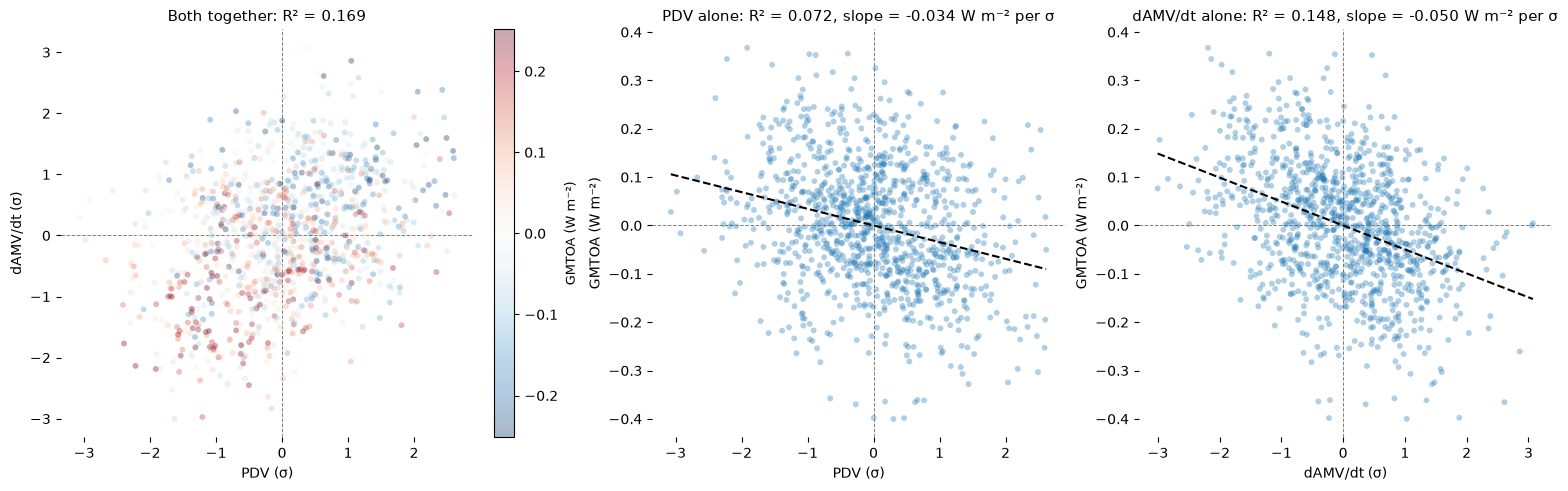

In [43]:
sc4 = build_scenario('PDV', 'dAMV')
summary(sc4)
scatter_row(sc4)

Classifying data with alpha=20...


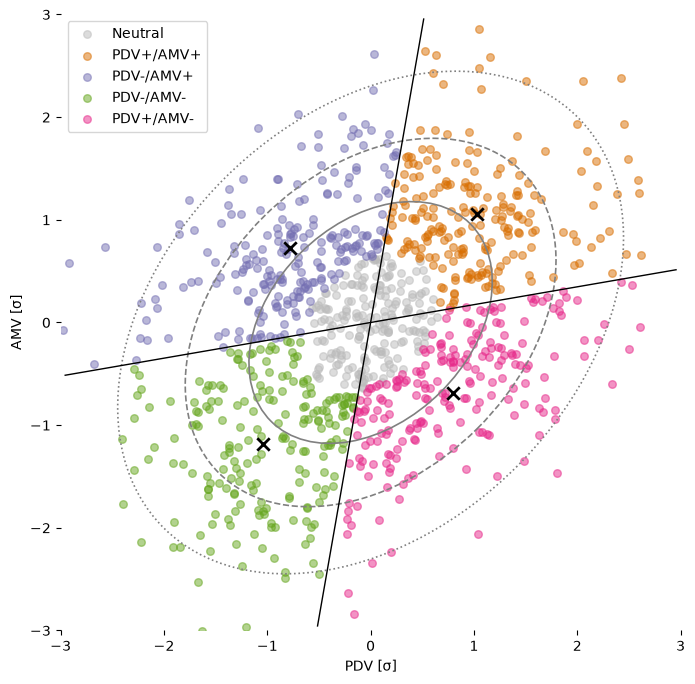

PDV-AMV correlation: r = +0.337
Neutral: 199 points
PDV+/AMV+: 215 points
PDV-/AMV+: 225 points
PDV-/AMV-: 208 points
PDV+/AMV-: 213 points

classes in the plane PDV (x) against dAMV/dt (y)
  neutral: 199 years
  PDV+ / dAMV/dt+: 215 years in 53 events
  PDV− / dAMV/dt+: 225 years in 53 events
  PDV− / dAMV/dt−: 208 years in 53 events
  PDV+ / dAMV/dt−: 213 years in 54 events


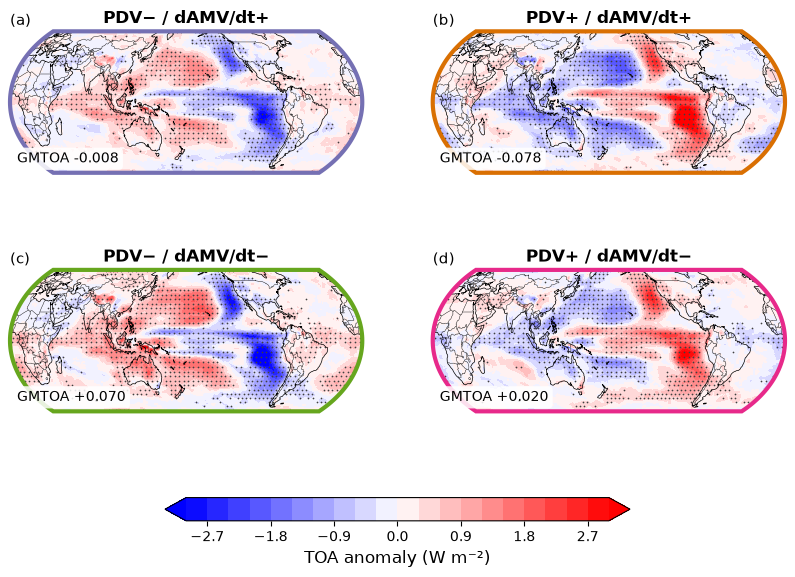

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


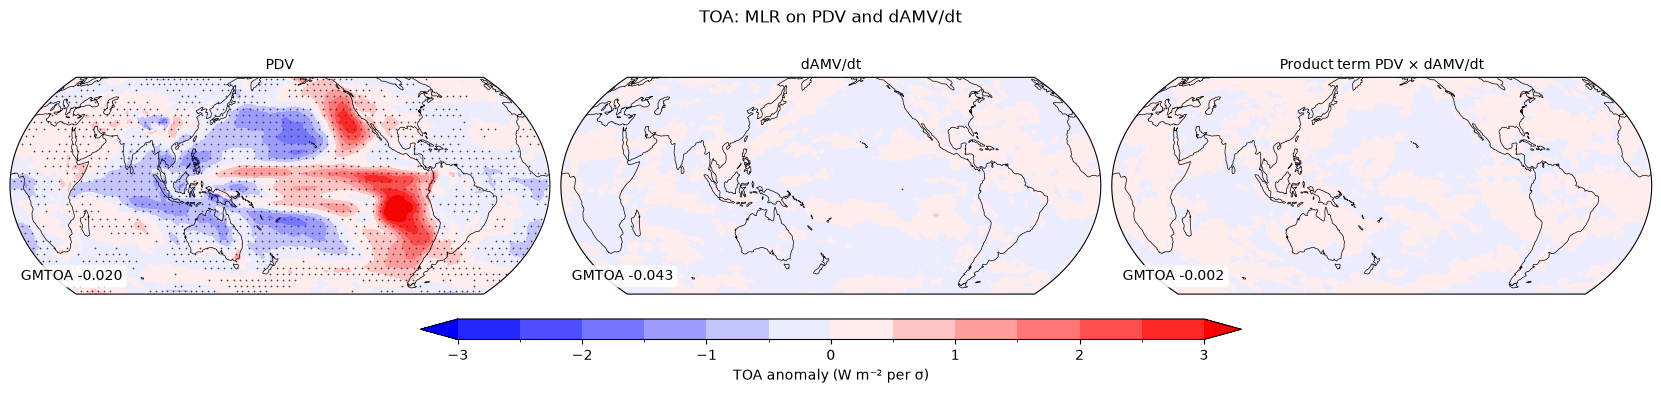

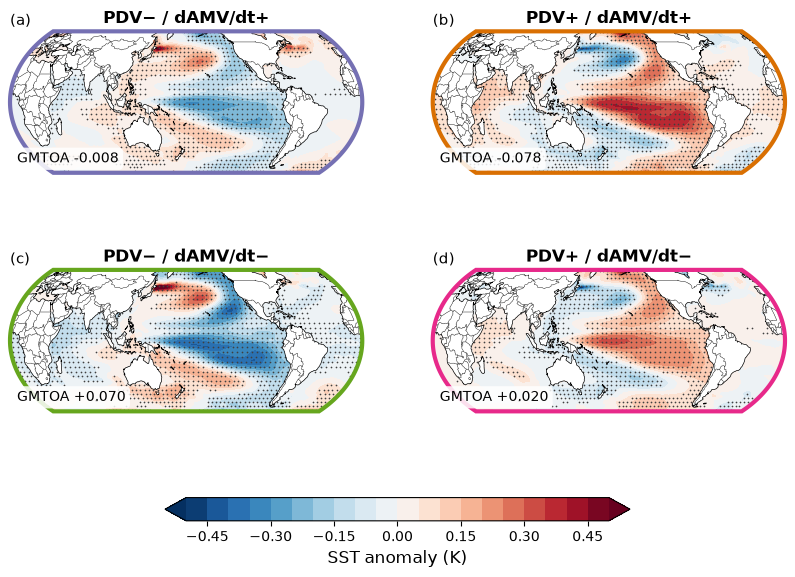

/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/liobabraun/opt/anaconda3/envs/thesisfig/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


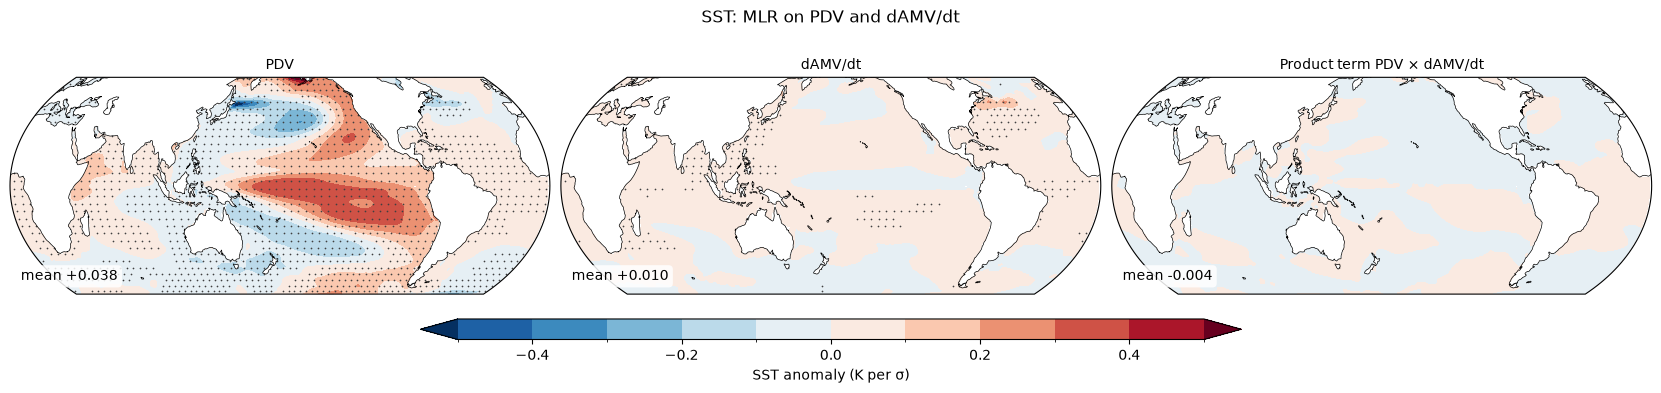

In [44]:
for field_name in map_fields:
    scenario_composites(sc4, field_name)
    if coefficient_maps:
        scenario_maps(sc4, field_name)

In [45]:
# coefficient maps: written once, read back on the next run (as in 04_piControl_state_transition)
if coef_cache_new:
    save_result(stack_store(coef_cache, ('coef', 'p'), ('scenario', 'field', 'term')), 'mlr_coef_maps')

---

## 5 Storyline composites

The storyline composites of the rest of the project: 110 non-overlapping decades, classified once in `02_piControl_decadal_storylines.ipynb` and read back from `data/piControl/decadal/`. Nothing is classified here and no threshold is used. This is where PDV+ and PDV−, AMV+ and AMV− are shown separately; the regressions above assume that the negative phase is the mirror image of the positive one.

**Check against scenario 1.** From the four storyline maps:

- PDV effect = ½[(PDV+/AMV+ + PDV+/AMV−) − (PDV−/AMV+ + PDV−/AMV−)]
- AMV effect = ½[(PDV+/AMV+ + PDV−/AMV+) − (PDV+/AMV− + PDV−/AMV−)]

The table gives the pattern correlation of each with the matching map of scenario 1. A value near 1 means the decade storylines and the Lanczos MLR show the same pattern. The maps of scenario 1 have to be drawn first.

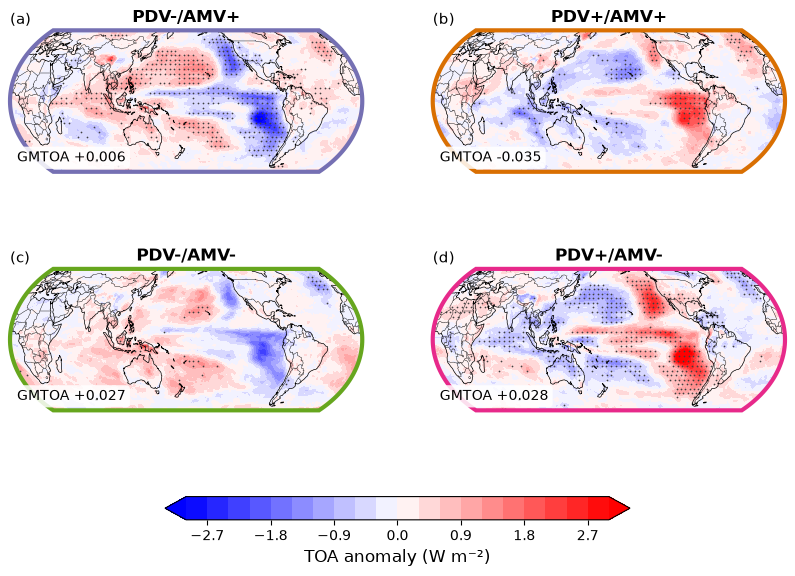

/Users/liobabraun/Desktop/Uni_Leipzig/MA/server/notebooks/functions.py:928: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  _, p_vals = stats.ttest_1samp(da.values, popmean=0, axis=0, nan_policy='omit')
/Users/liobabraun/Desktop/Uni_Leipzig/MA/server/notebooks/functions.py:928: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  _, p_vals = stats.ttest_1samp(da.values, popmean=0, axis=0, nan_policy='omit')
/Users/liobabraun/Desktop/Uni_Leipzig/MA/server/notebooks/functions.py:928: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentatio

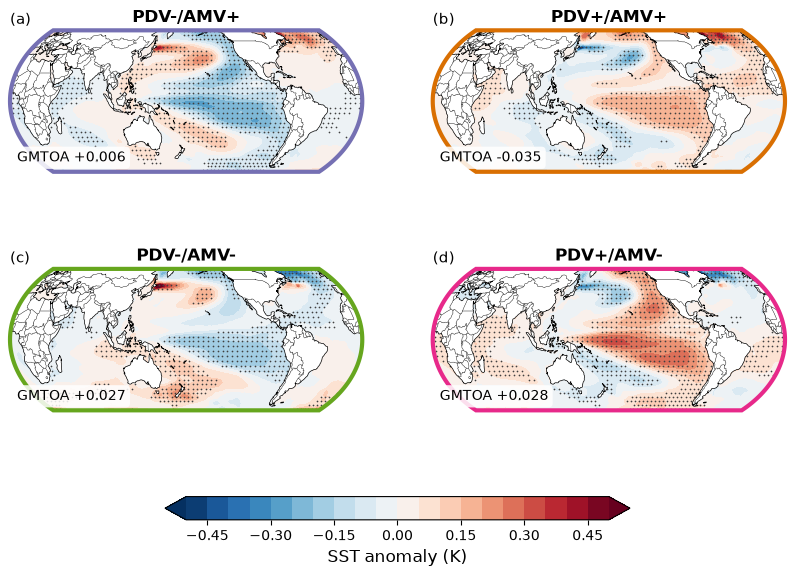

In [46]:
decadal = {name: xr.open_dataset(decadal_dir / f'{name}.nc') for name in map_fields}
storyline_means = {name: composite_means(ds) for name, ds in decadal.items()}

# GMTOA of each storyline, written into every panel whatever field it shows
toa_means = composite_means(xr.open_dataset(decadal_dir / 'TOA.nc'))
storyline_gmtoa = {i: float(global_mean(toa_means[i]['TOA'])) for i in toa_means}

for name, ds in decadal.items():
    sig = fdr_sig_masks(ds[name], ds['IVS'], alpha=alpha_fdr) if stippling else None
    fig = plot_ivs_2x2(
        storyline_means[name], variable=name, levels=composite_levels[name],
        cmap=map_cmaps[name], sig_masks=sig, lat_limit=lat_limit,
        cbar_label=f'{name} anomaly ({field_units[name]})',
        stipple_step=stipple_step, stipple_size=stipple_size, stipple_color=stipple_color,
    )
    annotate_gmtoa(fig, storyline_gmtoa)
    finish(fig, f'MLR_storylines_{name}')

In [47]:
# classes: 1 = PDV+/AMV+, 2 = PDV-/AMV+, 3 = PDV-/AMV-, 4 = PDV+/AMV-
# needs the coefficient maps of scenario 1 (coefficient_maps = True in the config)
rows = []
for name in map_fields:
    s = {i: storyline_means[name][i][name] for i in (1, 2, 3, 4)}
    effects = {
        'PDV': 0.5 * ((s[1] + s[4]) - (s[2] + s[3])),
        'AMV': 0.5 * ((s[1] + s[2]) - (s[4] + s[3])),
    }
    for term, effect in effects.items():
        rows.append({'field': name, 'effect': term,
                     'pattern correlation': pattern_correlation(effect, sc1.maps[(name, term)])})

print('storyline effects (decades) against the maps of scenario 1 (Lanczos MLR)')
display(pd.DataFrame(rows).round(2))

storyline effects (decades) against the maps of scenario 1 (Lanczos MLR)


,field,effect,pattern correlation
0,TOA,PDV,0.98
1,TOA,AMV,0.89
2,SST,PDV,0.98
3,SST,AMV,0.96
